## Build A Basic Chatbot With Langgraph(GRAPH API)

In [28]:
import os
from dotenv import load_dotenv
load_dotenv()

True

Annotated: Adds extra metadata or information to a type.

TypedDict: Defines the expected keys and data types of a state dictionary.

StateGraph: Creates a graph workflow in LangGraph.

START: Defines the starting point of the graph.

END: Defines the ending point of the graph.

add_messages: Merges new messages with the existing message history.

HumanMessage: Represents a message from the user.

AIMessage: Represents a response from the AI model.

SystemMessage: Provides instructions that guide the AI model's behavior.

Command: Controls graph execution, updates state, or resumes an interrupted graph.

InMemorySaver: Saves graph state checkpoints in memory.

create_agent: Creates an AI agent using a model, tools, and middleware.

SummarizationMiddleware: Summarizes older messages when conversation context grows.

HumanInTheLoopMiddleware: Pauses selected tool calls for human approval, editing, or rejection.

tool: Converts a Python function into a LangChain tool.

lambda: Creates a small anonymous function. It is a Python keyword, not an import.

In [29]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages:Annotated[list,add_messages]

In [30]:
from langchain.chat_models import init_chat_model

llm = init_chat_model(
    model="gemini-3.5-flash-lite",
    model_provider="google_genai"
)
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-google-genai': '4.4.0'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x00000268784E3DF0>, default_metadata=(), model_kwar

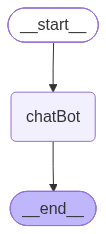

In [31]:
from IPython.display import Image, display

## node functionality
def chatBot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

graph_builder=StateGraph(State)

## adding nodes and edges
graph_builder.add_node("chatBot",chatBot)
graph_builder.add_edge(START,"chatBot")
graph_builder.add_edge("chatBot",END)

## compile
graph=graph_builder.compile()

## view the graph 
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass


In [32]:
response=graph.invoke({"messages":"Hii. How are you??"})
response

{'messages': [HumanMessage(content='Hii. How are you??', additional_kwargs={}, response_metadata={}, id='1c4b329a-3c83-4f20-8714-c1237d798868'),
  AIMessage(content=[{'type': 'text', 'text': "Hi! I'm doing well, thank you for asking. How are you doing today? How can I help you?", 'extras': {'signature': 'EmAKXgFpFH0TBk+q+tjq6JmoqeejOK9oXxW241NhrH3U4ghtAhaIy7ZWOlmp22TAWl+UeUP7jqKoKMMeXjoVSzJqhQzP7/oVOU29Zbmf+BwO+Bd7fgqnBvt/7yi4uPk2ceo='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a13aae-bd2d-7332-8ddc-b2abb0876220-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 25, 'total_tokens': 33, 'input_token_details': {'cache_read': 0}})]}

In [33]:
response["messages"][-1].content

[{'type': 'text',
  'text': "Hi! I'm doing well, thank you for asking. How are you doing today? How can I help you?",
  'extras': {'signature': 'EmAKXgFpFH0TBk+q+tjq6JmoqeejOK9oXxW241NhrH3U4ghtAhaIy7ZWOlmp22TAWl+UeUP7jqKoKMMeXjoVSzJqhQzP7/oVOU29Zbmf+BwO+Bd7fgqnBvt/7yi4uPk2ceo='}}]

## ChatBoat with Tools

In [ ]:
from langchain.tools import tool
import requests

llm = init_chat_model(
    model="gemini-3.5-flash-lite",
    model_provider="google_genai"
)

## tools.... 
def get_coordinates(address:str)->str:
    """
    This function converts an address or location name into latitude and longitude coordinates.
    Args:
        address(str): address
    Returns:
        str:output
    """
    url = "https://nominatim.openstreetmap.org/search"
    params={
        "q":address,
        "format":"jsonv2",
        "limit":1
    }
    headers = {
        "User-Agent": "MyStudentProject/1.0"
    }
    response=requests.get(
        url,
        params=params,
        headers=headers,
        timeout=15
    )
    response.raise_for_status()
    result=response.json()

    if not result:
        return "error : Location not found"
    
    return f"address:{result[0]["display_name"]}, latitude:{result[0]["lat"]}, longitude:{result[0]["lon"]}"


def get_weather(lat:float,lon:float)->str:
    """
    This function retrieves weather data for a given latitude and longitude.
    Args:
        lat (float): first int
        lon (float): second int
    Returns:
        str:output
    """
    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": lat,
            "longitude": lon,
            "current": "temperature_2m,wind_speed_10m"
        },
        timeout=15
    ).json()

    if response["current"]:
        data=response["current"]
        return (
            f"Time: {data['time']}, "
            f"Interval: {data['interval']} seconds, "
            f"Temperature: {data['temperature_2m']}°C, "
            f"Wind Speed: {data['wind_speed_10m']} km/h."
        )
    
    return "error : The service is overloaded"

# print(get_coordinates("Victoria Memorial, Kolkata, India"))
# get_weather(22.57,88.36)


## bind this tools with llms
llm_bind_tools=llm.bind_tools([get_weather,get_coordinates])
llm_bind_tools


_ChatModelBinding(bound=ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-google-genai': '4.4.0'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x0000026872EDC140>, default

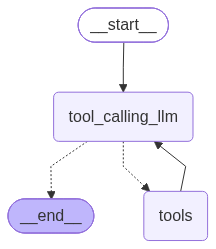

In [ ]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

class State(TypedDict):
    messages:Annotated[list,add_messages]

"""
is a LangGraph checkpointer that saves the graph state and
conversation history in RAM.
It supports resuming interrupted workflows.
"""
memory=MemorySaver()

## node functionality
def tool_calling_llm(state:State):
    return {"messages":[llm_bind_tools.invoke(state["messages"])]}

graph_builder=StateGraph(State)

## adding nodes and edges
graph_builder.add_node("tool_calling_llm",tool_calling_llm)
graph_builder.add_node("tools",ToolNode(tools=[get_coordinates,get_weather]))

graph_builder.add_edge(START,"tool_calling_llm")
graph_builder.add_conditional_edges(
    "tool_calling_llm",tools_condition
)
graph_builder.add_edge("tools","tool_calling_llm")
graph_builder.add_edge("tool_calling_llm",END)

## compile
graph=graph_builder.compile(checkpointer=memory)

## view the graph 
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [50]:
config={"configurable":{"thread_id":"user123"}}

In [51]:
response=graph.invoke({"messages":"My name is Susovan Paul. My friend name is Rahul Ghosh. what the weather of my and my friend location ?? I address is Deulpur, Howrah, 711411. My friend address is Garia, Kolkata"},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

My name is Susovan Paul. My friend name is Rahul Ghosh. what the weather of my and my friend location ?? I address is Deulpur, Howrah, 711411. My friend address is Garia, Kolkata
================================== Ai Message ==================================

[]
Tool Calls:
  get_coordinates (call_2772143)
 Call ID: call_2772143
  Args:
    address: Deulpur, Howrah, 711411
  get_coordinates (call_2772144)
 Call ID: call_2772144
  Args:
    address: Garia, Kolkata
================================= Tool Message =================================
Name: get_coordinates

address:PHC, Deulpur, NH16, Kolkata Metropolitan Area, Sankrail, Howrah, West Bengal, 711302, India, latitude:22.5998120, longitude:88.1644830
================================= Tool Message =================================
Name: get_coordinates

address:New Garia, Panchasayar Main Road, Panchasayar, Baghajatin, Kolkata, Kolkata Metropolitan A

In [52]:
response=graph.invoke({"messages":"what is my location? and what is my name?"},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

My name is Susovan Paul. My friend name is Rahul Ghosh. what the weather of my and my friend location ?? I address is Deulpur, Howrah, 711411. My friend address is Garia, Kolkata
================================== Ai Message ==================================

[]
Tool Calls:
  get_coordinates (call_2772143)
 Call ID: call_2772143
  Args:
    address: Deulpur, Howrah, 711411
  get_coordinates (call_2772144)
 Call ID: call_2772144
  Args:
    address: Garia, Kolkata
================================= Tool Message =================================
Name: get_coordinates

address:PHC, Deulpur, NH16, Kolkata Metropolitan Area, Sankrail, Howrah, West Bengal, 711302, India, latitude:22.5998120, longitude:88.1644830
================================= Tool Message =================================
Name: get_coordinates

address:New Garia, Panchasayar Main Road, Panchasayar, Baghajatin, Kolkata, Kolkata Metropolitan A

In [53]:
response=graph.invoke({"messages":"what is Rahul's location? and who is Rahul?"},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

My name is Susovan Paul. My friend name is Rahul Ghosh. what the weather of my and my friend location ?? I address is Deulpur, Howrah, 711411. My friend address is Garia, Kolkata
================================== Ai Message ==================================

[]
Tool Calls:
  get_coordinates (call_2772143)
 Call ID: call_2772143
  Args:
    address: Deulpur, Howrah, 711411
  get_coordinates (call_2772144)
 Call ID: call_2772144
  Args:
    address: Garia, Kolkata
================================= Tool Message =================================
Name: get_coordinates

address:PHC, Deulpur, NH16, Kolkata Metropolitan Area, Sankrail, Howrah, West Bengal, 711302, India, latitude:22.5998120, longitude:88.1644830
================================= Tool Message =================================
Name: get_coordinates

address:New Garia, Panchasayar Main Road, Panchasayar, Baghajatin, Kolkata, Kolkata Metropolitan A